## Post-hoc calibration

### Install packages/libraries

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, accuracy_score, roc_auc_score
from scipy.stats import spearmanr

### Implement Platt scaling

Load the predictions.

In [4]:
cal_df = pd.read_csv("../data/processed/calibration.csv")
test_df = pd.read_csv("../data/processed/test.csv")

def load_predictions(filename, expected_rows):
    predictions = pd.read_csv(f"../results/{filename}")

    assert len(predictions) == expected_rows
    assert predictions["row_id"].is_unique
    assert set(predictions["row_id"]) == set(range(expected_rows))
    assert predictions["llm_probability"].notna().all()

    return predictions.sort_values("row_id").reset_index(drop=True)


direct_cal = load_predictions("direct_calibration.csv", len(cal_df))
direct_test = load_predictions("direct_test.csv", len(test_df))

structured_cal = load_predictions("structured_calibration.csv", len(cal_df))
structured_test = load_predictions("structured_test.csv", len(test_df))

Define Platt scaling.

In [5]:
def platt_scale(cal_prob, cal_y, test_prob):

    cal_prob = np.asarray(cal_prob).reshape(-1, 1)
    test_prob = np.asarray(test_prob).reshape(-1, 1)
    cal_y = np.asarray(cal_y).astype(int)

    calibrator = LogisticRegression(
        max_iter=1000
    )

    calibrator.fit(cal_prob, cal_y)

    calibrated_test_prob = calibrator.predict_proba(
        test_prob
    )[:, 1]

    return calibrator, calibrated_test_prob

Calibrate direct prompting.

In [6]:
direct_calibrator, direct_calibrated_prob = platt_scale(
    direct_cal["llm_probability"],
    cal_df["TARGET_OVER"],
    direct_test["llm_probability"]
)

direct_results = test_df.copy()

direct_results["ORIGINAL_PROB"] = direct_test["llm_probability"].to_numpy()
direct_results["CALIBRATED_PROB"] = direct_calibrated_prob

Calibrate structured prompting.

In [7]:
structured_calibrator, structured_calibrated_prob = platt_scale(
    structured_cal["llm_probability"],
    cal_df["TARGET_OVER"],
    structured_test["llm_probability"]
)

structured_results = test_df.copy()

structured_results["ORIGINAL_PROB"] = structured_test["llm_probability"].to_numpy()
structured_results["CALIBRATED_PROB"] = structured_calibrated_prob

## Evaluate Platt scaling

Evaluation functions from LLM experiments.

In [8]:
def expected_calibration_error(y_true, y_prob, n_bins=5):

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(y_prob, bin_edges[1:-1], right=True)

    ece = 0.0

    for i in range(n_bins):

        mask = bin_ids == i

        if mask.sum() == 0:
            continue

        avg_confidence = y_prob[mask].mean()
        actual_frequency = y_true[mask].mean()

        ece += (
            mask.sum() / len(y_true)
        ) * abs(avg_confidence - actual_frequency)

    return ece


def evaluate_predictions(data, probability_column):

    y_true = data["TARGET_OVER"].astype(int)
    y_prob = data[probability_column].astype(float)

    return {
        "Brier Score": brier_score_loss(y_true, y_prob),
        "ECE": expected_calibration_error(y_true, y_prob),
        "Accuracy": accuracy_score(y_true, y_prob >= 0.5)
    }

Compare results.

In [9]:
comparison = pd.DataFrame({
    "Direct (Original)": evaluate_predictions(
        direct_results, "ORIGINAL_PROB"
    ),
    "Direct (Platt)": evaluate_predictions(
        direct_results, "CALIBRATED_PROB"
    ),
    "Structured (Original)": evaluate_predictions(
        structured_results, "ORIGINAL_PROB"
    ),
    "Structured (Platt)": evaluate_predictions(
        structured_results, "CALIBRATED_PROB"
    )
}).T

display(comparison.round(4))

,Brier Score,ECE,Accuracy
Direct (Original),0.2513,0.0583,0.5434
Direct (Platt),0.2510,0.0235,0.4566
Structured (Original),0.2435,0.0305,0.5845
Structured (Platt),0.2520,0.0231,0.4155


Save results.

In [10]:
direct_results[["ORIGINAL_PROB", "CALIBRATED_PROB"]].to_csv(
    "../results/direct_platt_test.csv",
    index=False
)

structured_results[["ORIGINAL_PROB", "CALIBRATED_PROB"]].to_csv(
    "../results/structured_platt_test.csv",
    index=False
)

comparison.to_csv("../results/platt_comparison.csv")

## Diagnose results

In [11]:
for name, results in [
    ("Direct", direct_results),
    ("Structured", structured_results)
]:
    print(f"\n{name}")

    for column in ["ORIGINAL_PROB", "CALIBRATED_PROB"]:
        p = results[column]

        print(f"{column}:")
        print(f"  Mean: {p.mean():.4f}")
        print(f"  Std: {p.std():.4f}")
        print(f"  Min: {p.min():.4f}")
        print(f"  Max: {p.max():.4f}")
        print(f"  Predicted Over: {(p >= 0.5).mean():.2%}")

print("\nActual Over rates:")
print(f"Calibration: {cal_df['TARGET_OVER'].mean():.4f}")
print(f"Test: {test_df['TARGET_OVER'].mean():.4f}")

print("\nPlatt coefficients:")
print("Direct:", direct_calibrator.coef_, direct_calibrator.intercept_)
print("Structured:", structured_calibrator.coef_, structured_calibrator.intercept_)


Direct
ORIGINAL_PROB:
  Mean: 0.5192
  Std: 0.1062
  Min: 0.3000
  Max: 0.7500
  Predicted Over: 55.25%
CALIBRATED_PROB:
  Mean: 0.5030
  Std: 0.0075
  Min: 0.4866
  Max: 0.5185
  Predicted Over: 49.32%

Structured
ORIGINAL_PROB:
  Mean: 0.4932
  Std: 0.1037
  Min: 0.2800
  Max: 0.7200
  Predicted Over: 43.84%
CALIBRATED_PROB:
  Mean: 0.5026
  Std: 0.0108
  Min: 0.4791
  Max: 0.5247
  Predicted Over: 56.16%

Actual Over rates:
Calibration: 0.5046
Test: 0.4795

Platt coefficients:
Direct: [[-0.28392712]] [0.15936343]
Structured: [[-0.41505129]] [0.21504741]


In [12]:
for name, predictions in [
    ("Direct", direct_cal),
    ("Structured", structured_cal)
]:
    p = predictions["llm_probability"].to_numpy()
    y = cal_df["TARGET_OVER"].astype(int).to_numpy()

    correlation, _ = spearmanr(p, y)
    auc = roc_auc_score(y, p)

    print(f"\n{name}")
    print(f"Spearman correlation: {correlation:.4f}")
    print(f"ROC AUC: {auc:.4f}")


Direct
Spearman correlation: -0.0180
ROC AUC: 0.4897

Structured
Spearman correlation: -0.0794
ROC AUC: 0.4546


In [13]:
for name, predictions in [
    ("Direct", direct_test),
    ("Structured", structured_test)
]:
    auc = roc_auc_score(
        test_df["TARGET_OVER"].astype(int),
        predictions["llm_probability"]
    )

    print(f"{name} Test AUC: {auc:.4f}")

Direct Test AUC: 0.5518
Structured Test AUC: 0.5850


Reliability diagrams.

In [16]:
test_df = pd.read_csv("../data/processed/test.csv")

results_dir = Path("../results")

direct_test = pd.read_csv(results_dir / "direct_test.csv")
structured_test = pd.read_csv(results_dir / "structured_test.csv")
lr_test = pd.read_csv(results_dir / "logistic_regression_test.csv")
direct_platt = pd.read_csv(results_dir / "direct_platt_test.csv")
structured_platt = pd.read_csv(results_dir / "structured_platt_test.csv")

def aligned_predictions(predictions, column, n_rows):
    if "row_id" in predictions.columns:
        assert predictions["row_id"].is_unique
        assert set(predictions["row_id"]) == set(range(n_rows))
        predictions = predictions.sort_values("row_id")

    assert len(predictions) == n_rows
    values = predictions[column].to_numpy(dtype=float)

    assert np.isfinite(values).all()
    assert ((values >= 0) & (values <= 1)).all()

    return values


y_test = test_df["TARGET_OVER"].astype(int).to_numpy()

probabilities = {
    "Historical Frequency": test_df["HIST_OVER_RATE_L10"].to_numpy(),
    "Constant Probability": np.full(
        len(test_df),
        pd.read_csv("../data/processed/train.csv")["TARGET_OVER"].mean()
    ),
    "Logistic Regression": aligned_predictions(
        lr_test, "lr_probability", len(test_df)
    ),
    "LLM Direct": aligned_predictions(
        direct_test, "llm_probability", len(test_df)
    ),
    "LLM Structured": aligned_predictions(
        structured_test, "llm_probability", len(test_df)
    ),
    "Direct + Platt": aligned_predictions(
        direct_platt, "CALIBRATED_PROB", len(test_df)
    ),
    "Structured + Platt": aligned_predictions(
        structured_platt, "CALIBRATED_PROB", len(test_df)
    )
}

Define reliability diagram function.

In [17]:
def reliability_data(y_true, y_prob, n_bins=5):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(
        y_prob,
        bin_edges[1:-1],
        right=True
    )

    rows = []

    for i in range(n_bins):
        mask = bin_ids == i
        count = mask.sum()

        if count == 0:
            continue

        rows.append({
            "bin": i,
            "count": count,
            "mean_predicted": y_prob[mask].mean(),
            "fraction_positive": y_true[mask].mean()
        })

    return pd.DataFrame(rows)


def plot_reliability(ax, y_true, y_prob, label, n_bins=5):
    data = reliability_data(y_true, y_prob, n_bins)

    ax.plot(
        data["mean_predicted"],
        data["fraction_positive"],
        marker="o",
        linewidth=2,
        label=label
    )

    return data

Compare all original models.

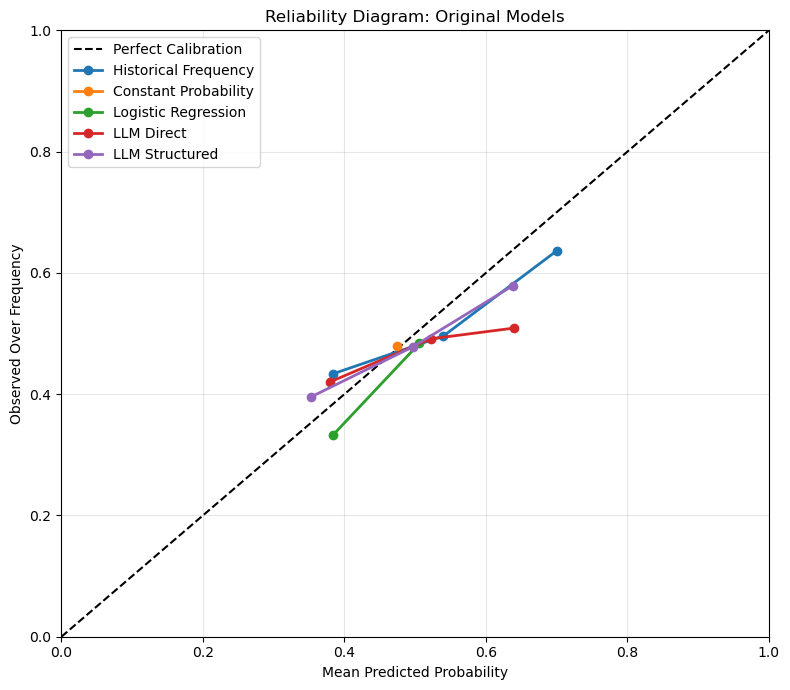

In [20]:
original_models = [
    "Historical Frequency",
    "Constant Probability",
    "Logistic Regression",
    "LLM Direct",
    "LLM Structured"
]

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Perfect Calibration"
)

for model in original_models:
    plot_reliability(
        ax,
        y_test,
        probabilities[model],
        model
    )

ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Over Frequency")
ax.set_title("Reliability Diagram: Original Models")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(
    results_dir / "reliability_original_models.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Compare Platt scaling.

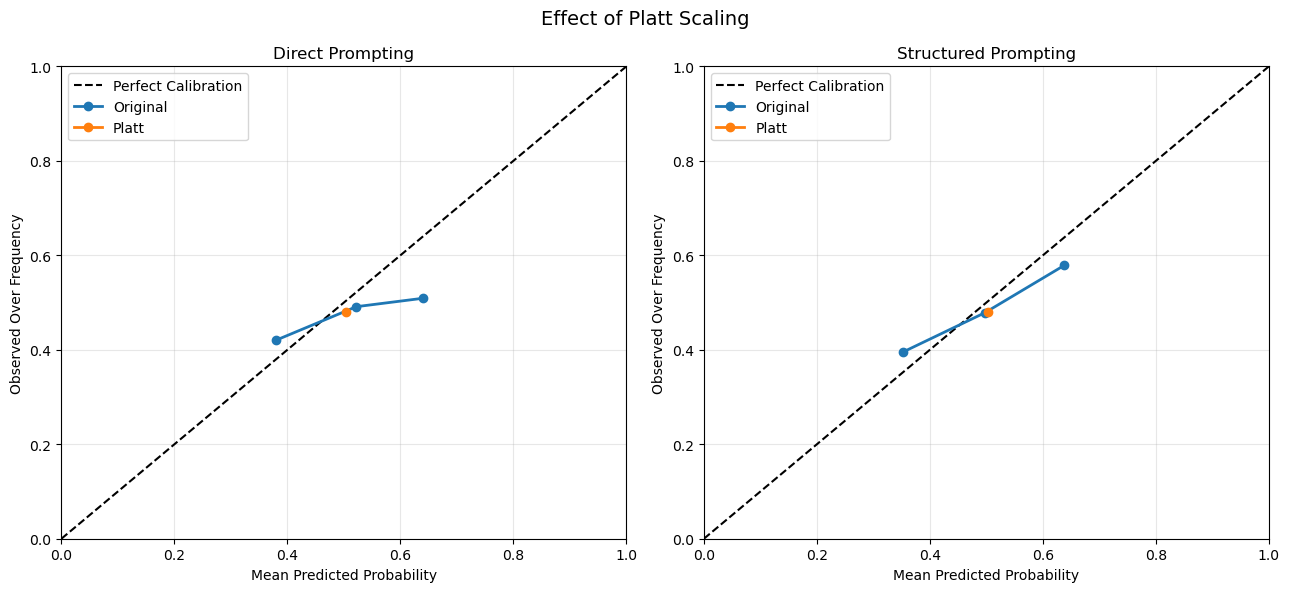

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

comparisons = [
    ("Direct Prompting", "LLM Direct", "Direct + Platt"),
    ("Structured Prompting", "LLM Structured", "Structured + Platt")
]

for ax, (title, original, calibrated) in zip(axes, comparisons):

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="black",
        label="Perfect Calibration"
    )

    plot_reliability(
        ax, y_test, probabilities[original], "Original"
    )

    plot_reliability(
        ax, y_test, probabilities[calibrated], "Platt"
    )

    ax.set_title(title)
    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Observed Over Frequency")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Effect of Platt Scaling", fontsize=14)
plt.tight_layout()

plt.savefig(
    results_dir / "reliability_platt_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Generate individual reliability diagrams.

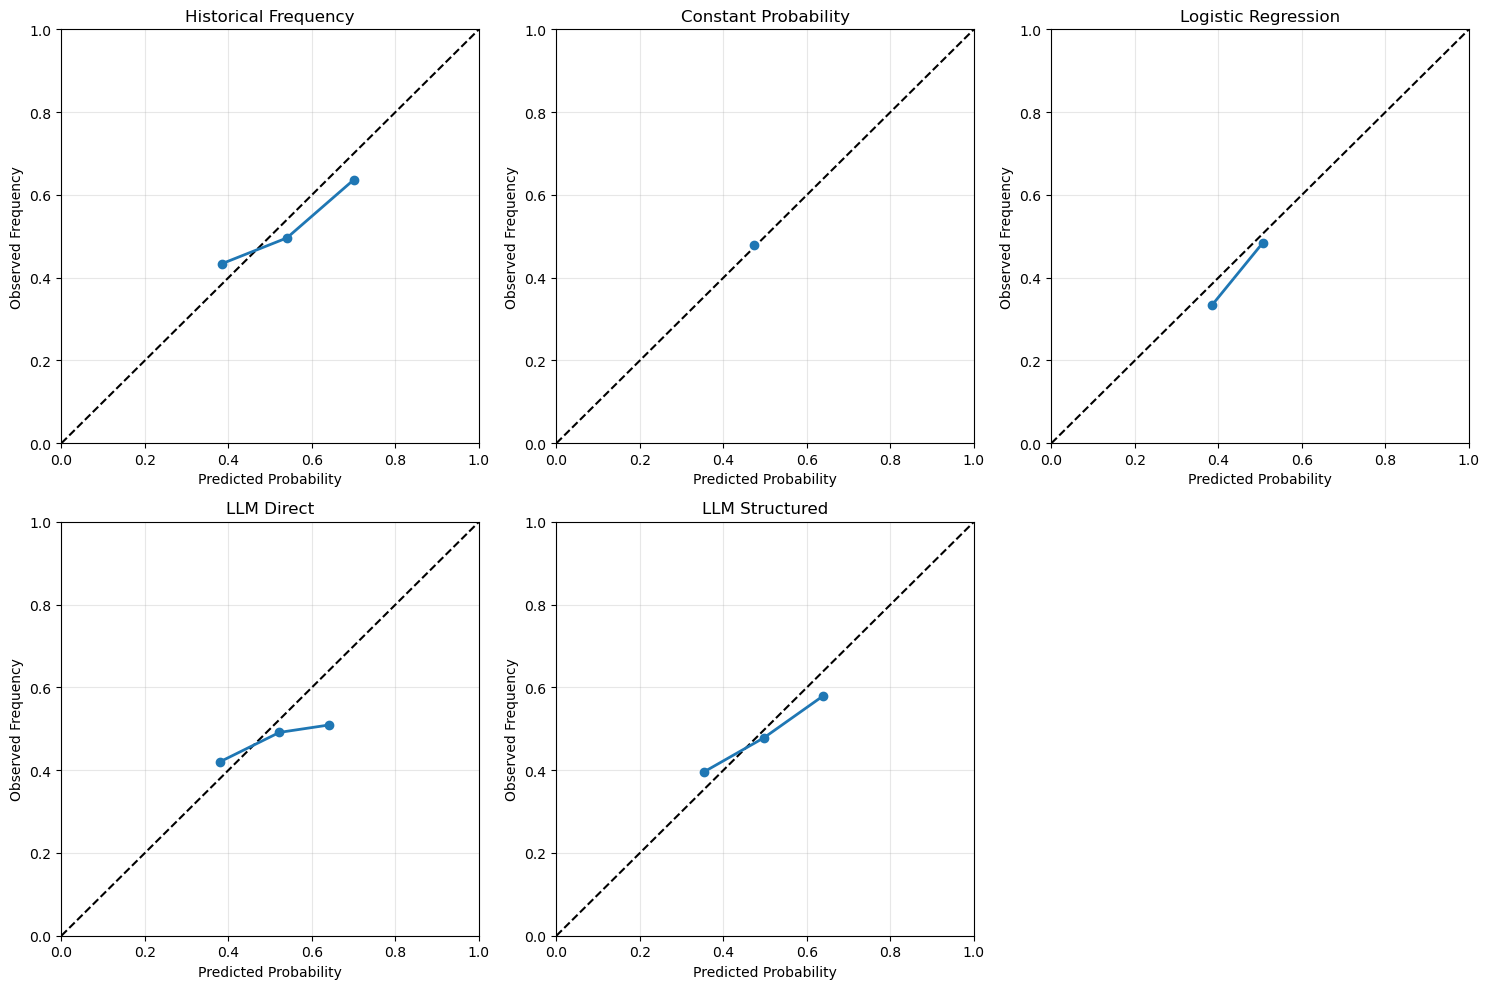

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, model in zip(axes.flat, original_models):

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="black"
    )

    data = plot_reliability(
        ax,
        y_test,
        probabilities[model],
        model
    )

    ax.set_title(model)
    ax.set_xlabel("Predicted Probability")
    ax.set_ylabel("Observed Frequency")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)

for ax in axes.flat[len(original_models):]:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    results_dir / "reliability_individual_models.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Inspect bin counts.

In [24]:
for model in probabilities:

    data = reliability_data(
        y_test,
        probabilities[model]
    )

    print(f"\n{model}")
    display(data.round(4))


Historical Frequency


,bin,count,mean_predicted,fraction_positive
0,1,83,0.3843,0.4337
1,2,125,0.5400,0.4960
2,3,11,0.7000,0.6364



Constant Probability


,bin,count,mean_predicted,fraction_positive
0,2,219,0.4739,0.4795



Logistic Regression


,bin,count,mean_predicted,fraction_positive
0,1,6,0.3844,0.3333
1,2,213,0.5058,0.4836


... (4 outputs left out)


Direct + Platt


,bin,count,mean_predicted,fraction_positive
0,2,219,0.503,0.4795



Structured + Platt


,bin,count,mean_predicted,fraction_positive
0,2,219,0.5026,0.4795


## Implement player-clustered paired bootstrap confidence intervals

Define bootstrap function.

In [26]:
def player_cluster_bootstrap(
    data,
    model_a,
    model_b,
    n_bootstrap=10000,
    random_state=42
):
    rng = np.random.default_rng(random_state)

    players = data["PLAYER_ID"].unique()

    clusters = {
        player: data[data["PLAYER_ID"] == player]
        for player in players
    }

    y = data["TARGET_OVER"].to_numpy()

    observed_diff = (
        brier_score_loss(y, data[model_a])
        - brier_score_loss(y, data[model_b])
    )

    bootstrap_diffs = []

    for _ in range(n_bootstrap):

        sampled_players = rng.choice(
            players,
            size=len(players),
            replace=True
        )

        sample = pd.concat(
            [clusters[player] for player in sampled_players],
            ignore_index=True
        )

        y_sample = sample["TARGET_OVER"].to_numpy()

        diff = (
            brier_score_loss(y_sample, sample[model_a])
            - brier_score_loss(y_sample, sample[model_b])
        )

        bootstrap_diffs.append(diff)

    bootstrap_diffs = np.asarray(bootstrap_diffs)

    ci_lower, ci_upper = np.percentile(
        bootstrap_diffs,
        [2.5, 97.5]
    )

    return {
        "Observed Difference": observed_diff,
        "CI Lower": ci_lower,
        "CI Upper": ci_upper,
        "Excludes Zero": ci_lower > 0 or ci_upper < 0
    }

Prepare comparison dataframe.

In [27]:
bootstrap_df = test_df[
    ["PLAYER_ID", "TARGET_OVER"]
].copy().reset_index(drop=True)

bootstrap_df["Structured"] = probabilities["LLM Structured"]
bootstrap_df["Direct"] = probabilities["LLM Direct"]
bootstrap_df["Logistic Regression"] = probabilities["Logistic Regression"]
bootstrap_df["Historical Frequency"] = probabilities["Historical Frequency"]

assert len(bootstrap_df) == 219
assert bootstrap_df.notna().all().all()

display(bootstrap_df.head())

,PLAYER_ID,TARGET_OVER,Structured,Direct,Logistic Regression,Historical Frequency
0,2544,0.0,0.42,0.45,0.517878,0.6
1,203999,0.0,0.58,0.58,0.431855,0.6
2,1627759,0.0,0.57,0.64,0.519343,0.4
3,1629027,0.0,0.28,0.36,0.576403,0.4
4,1629636,1.0,0.62,0.57,0.545783,0.7


Run bootstrap comparisons.

In [28]:
comparisons = [
    "Direct",
    "Logistic Regression",
    "Historical Frequency"
]

results = {}

for comparison in comparisons:

    results[f"Structured vs {comparison}"] = player_cluster_bootstrap(
        bootstrap_df,
        model_a="Structured",
        model_b=comparison,
        n_bootstrap=10000,
        random_state=42
    )

bootstrap_results = pd.DataFrame(results).T

display(bootstrap_results.round(4))

,Observed Difference,CI Lower,CI Upper,Excludes Zero
Structured vs Direct,-0.007752,-0.015124,-0.000541,True
Structured vs Logistic Regression,-0.004672,-0.02016,0.008688,False
Structured vs Historical Frequency,-0.004491,-0.017817,0.006121,False


Visualize confidence intervals.

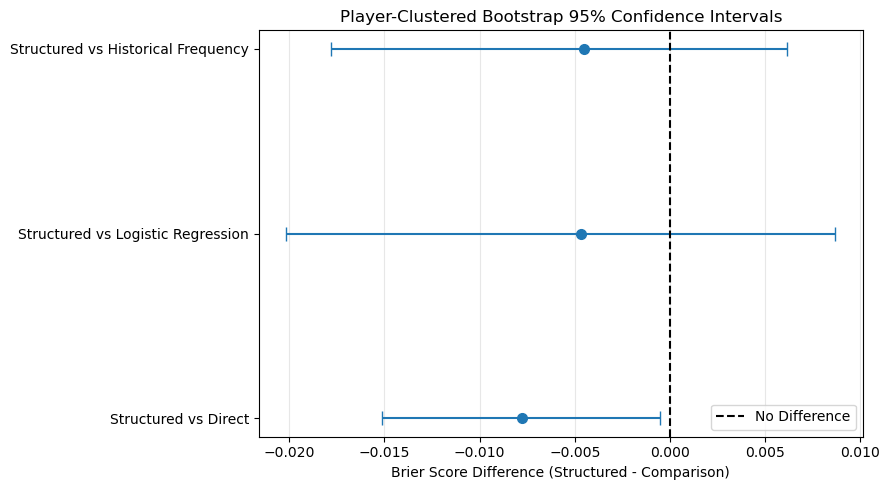

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))

labels = bootstrap_results.index.tolist()

estimates = bootstrap_results["Observed Difference"].astype(float)
lower = bootstrap_results["CI Lower"].astype(float)
upper = bootstrap_results["CI Upper"].astype(float)

positions = np.arange(len(labels))

ax.errorbar(
    estimates,
    positions,
    xerr=[
        estimates - lower,
        upper - estimates
    ],
    fmt="o",
    capsize=5,
    markersize=7
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    label="No Difference"
)

ax.set_yticks(positions)
ax.set_yticklabels(labels)

ax.set_xlabel(
    "Brier Score Difference (Structured - Comparison)"
)
ax.set_title(
    "Player-Clustered Bootstrap 95% Confidence Intervals"
)

ax.grid(axis="x", alpha=0.3)
ax.legend()

plt.tight_layout()

plt.savefig(
    "../results/bootstrap_brier_confidence_intervals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
bootstrap_results.to_csv(
    "../results/bootstrap_brier_results.csv"
)

print("Bootstrap results saved.")

Bootstrap results saved.
